In [1]:
import sys
from pathlib import Path

import matplotlib_fontja  # noqa: F401

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path))
        break

    if (path / "src" / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path / "src"))
        break

from common.notebook_style import apply_dataframe_style

apply_dataframe_style()

In [2]:
import pandas as pd


def format_table_for_display(df):
    display_df = df.copy()
    for column in display_df.columns:
        if column in {"customer_id", "rank", "frequency"}:
            display_df[column] = display_df[column].map(
                lambda value: f"{value:.0f}"
            )
        elif column in {"recency", "T", "predicted_purchases"}:
            display_df[column] = display_df[column].map(
                lambda value: f"{value:.2f}"
            )
        elif column == "prob_alive":
            display_df[column] = display_df[column].map(
                lambda value: f"{value:.2%}"
            )
        elif column == "cumulative_ltv_pct":
            display_df[column] = display_df[column].map(
                lambda value: f"{value:.2f}%"
            )
        elif column in {"monetary_value", "LTV"}:
            display_df[column] = display_df[column].map(
                lambda value: f"{value:,.0f}"
            )
        elif pd.api.types.is_float_dtype(display_df[column]):
            display_df[column] = display_df[column].map(
                lambda value: f"{value:.2f}"
            )
    return display_df

/Users/hiroshi/private/marketing_science/envs/py314-main/.venv/lib/python3.14/site-packages/requests/__init__.py:109: RequestsDependencyWarning: urllib3 (1.26.13) or chardet (7.4.3)/charset_normalizer (2.1.1) doesn't match a supported version!
  warnings.warn(


# 第10章 優良顧客を見極める


## 第10章、第4節、第1項のコード

### データ準備：トランザクションログからRFMのサマリーテーブルへの変換 — 入力データの形式

BG/NBDモデルの仮定（ポアソン過程による購買・購買率の個人差をガンマ分布で表す方法・離反確率の個人差をベータ分布で表す方法）に沿ったシミュレーションデータを生成し、トランザクションログを作成する。

#### 処理内容

1. **シミュレーションパラメータの設定**
   顧客数3000名、観測期間2022-01-01〜2022-12-31（364日）を設定する。

2. **BG/NBDの仮定に沿ったデータ生成**
   顧客ごとの週あたりの購買率 `lambda ~ Gamma(r, 1/alpha_w)` および離反確率 `p_drop ~ Beta(a, b)` を生成し、指数分布に基づいて購買間隔を仮想的に生成する。また、購買金額はガンマ-ガンマモデルに沿って2段階で生成する（`nu_i ~ Gamma(q, rate=v)` → `amount ~ Gamma(p, rate=nu_i)`）。購買金額のおおむね40%を粗利、残りを原価として記録する。

3. **トランザクションログの作成**
   生成した購買データを PolarsのDataFrame として整形し、ユニーク顧客数と総トランザクション数を確認する。


In [3]:
import numpy as np
import polars as pl

# シミュレーションデータの生成
# 実務では実際のPOS（販売時点情報管理）データ・ECログを使用
rng = np.random.default_rng(123)

n_customers = 3000
observation_start = np.datetime64("2022-01-01")
observation_end = np.datetime64("2022-12-31")  # 分析の基準日（52週）
obs_days = int((observation_end - observation_start) / np.timedelta64(1, "D"))

# BG/NBDの仮定に沿ったシミュレーション
# lambda_w ~ Gamma(r, 1/alpha_w)：顧客ごとの週あたりの購買率
# p_drop   ~ Beta(a, b)          ：購買ごとの離反確率
#
# シナリオ：ロイヤルティプログラム会員。入会日（Jan 1）に全員が初回の購買をし、
#           その後の購買行動を52週（1年間）観察。
# → r=0.5（値の小さい側に顧客が多いJ型のガンマ分布）
# → a=0.5, b=2.5（値の小さい側に顧客が多いJ型のベータ分布）
# → 金額：ガンマ-ガンマモデルに沿って2段階で生成
r, alpha_w = 0.5, 1.25  # E[λ_weekly] = r/alpha_w = 0.4（週0.4回 ≈ 月1.7回）
a, b = 0.5, 2.5  # E[p_drop] = a/(a+b) = 0.17（購買後の離反確率17%）
lambda_scale_daily = 1.0 / (alpha_w * 7)

lambdas = rng.gamma(r, lambda_scale_daily, size=n_customers)
dropout_prob = rng.beta(a, b, size=n_customers)

# nu_i ~ Gamma(q, rate=v), amount | nu_i ~ Gamma(p, rate=nu_i)
amount_p, amount_q, amount_v = 2.0, 3.0, 6000.0
gross_margin_rate = 0.40
customer_amount_rates = rng.gamma(
    shape=amount_q, scale=1.0 / amount_v, size=n_customers
)

rows = []
for cid in range(1, n_customers + 1):
    lam = lambdas[cid - 1]
    p_drop = dropout_prob[cid - 1]
    nu_i = customer_amount_rates[cid - 1]
    # 入会日（Jan 1）に初回の購買
    first_amount = max(1, int(rng.gamma(amount_p, 1.0 / nu_i)))
    first_gross_profit = max(1, int(first_amount * gross_margin_rate))
    rows.append(
        {
            "customer_id": cid,
            "date": str(observation_start),
            "amount": first_amount,
            "cost": first_amount - first_gross_profit,
            "gross_profit": first_gross_profit,
        }
    )

    # 購買率が極端に低い顧客は追加購買を発生させない
    if lam < 1e-8:
        continue

    # リピート購買（2回目以降）
    t = 0.0  # 初回の購買からの経過日数
    while True:
        t += rng.exponential(1.0 / lam)
        if t > obs_days:
            break
        date = str(
            observation_start + np.timedelta64(min(int(t), obs_days - 1), "D")
        )
        amount = max(1, int(rng.gamma(amount_p, 1.0 / nu_i)))
        gross_profit = max(1, int(amount * gross_margin_rate))
        rows.append(
            {
                "customer_id": cid,
                "date": date,
                "amount": amount,
                "cost": amount - gross_profit,
                "gross_profit": gross_profit,
            }
        )
        if rng.random() < p_drop:
            break

transaction_log = (
    pl.DataFrame(rows)
    .with_columns(pl.col("date").str.to_date().alias("date"))
    .sort(["customer_id", "date"])
)

print(f"ユニーク顧客数: {transaction_log['customer_id'].n_unique()}")
print(f"総トランザクション数: {len(transaction_log)}")

transaction_log_head = transaction_log.head()
transaction_log_head

ユニーク顧客数: 3000
総トランザクション数: 26255


customer_id,date,amount,cost,gross_profit
i64,date,i64,i64,i64
1,2022-01-01,798,479,319
1,2022-01-16,4597,2759,1838
1,2022-01-21,1373,824,549
1,2022-01-24,1225,735,490
1,2022-01-31,912,548,364


## 第10章、第4節、第1項のコード

### データ準備：RFMのサマリーテーブルへの変換

`lifetimes.utils.summary_data_from_transaction_data` を使って、トランザクションログを顧客ごとに集計したRFMのサマリーテーブル（frequency, recency, T, monetary_value）に変換する。

#### 処理内容

1. **pandas 変換**
   `lifetimes` ライブラリは pandasのDataFrame を受け取るため、PolarsのDataFrame を pandas に変換する。

2. **RFMのサマリーテーブルの作成**
   `summary_data_from_transaction_data` で同じ顧客の同じ日の取引を1回の購買機会にまとめ、recency と T は週単位に換算する。frequency は初回の購買日を除く購買日数、monetary_value は購買日ごとの合計粗利の平均であり、リピート購買がない顧客は 0 になる。

3. **Polars への変換**
   集計結果を PolarsのDataFrame に戻して確認する。


In [4]:
from lifetimes.utils import summary_data_from_transaction_data

# lifetimes 用のサマリーテーブルを作成
# pandasのDataFrameが必要なため変換
transaction_log_pd = transaction_log.to_pandas()
transaction_log_pd["date"] = transaction_log_pd["date"].astype(str)

rfm_df = summary_data_from_transaction_data(
    transactions=transaction_log_pd,
    customer_id_col="customer_id",
    datetime_col="date",
    monetary_value_col="gross_profit",
    observation_period_end=observation_end,
    freq="D",  # 同じ日の購買は1回の購買機会にまとめる
    freq_multiplier=7,  # recencyとTを週単位に換算
)

# Polars に戻して扱う
rfm_pl = pl.from_pandas(rfm_df.reset_index())

print(f"行数（ユニーク顧客数）: {len(rfm_pl)}")
rfm_head = rfm_pl.head(5)
rfm_head

行数（ユニーク顧客数）: 3000


customer_id,frequency,recency,T,monetary_value
i64,f64,f64,f64,f64
1,22.0,50.857143,52.0,672.772727
2,1.0,6.285714,52.0,794.0
3,1.0,46.857143,52.0,2889.0
4,6.0,7.571429,52.0,453.333333
5,4.0,22.571429,52.0,1428.75


## 第10章、第4節、第1項のコード

### データ準備：RFMのサマリーテーブルの確認と前処理 — 基本的な分布の確認

生成されたRFMのサマリーテーブルの分布（追加の購買日数・初回の購買から最終の購買までの経過週・購買日ごとの平均粗利）を matplotlib でヒストグラム表示して確認する。

#### 処理内容

1. **購買頻度の分布の図示**
   `frequency`（追加の購買日数）のヒストグラムを描く。

2. **Recencyの分布の図示**
   `recency`（初回の購買から最終の購買までの経過週）のヒストグラムを描く。

3. **購買日ごとの平均粗利の分布の図示**
   `monetary_value > 0` の顧客に絞って購買日ごとの平均粗利のヒストグラムを描く。


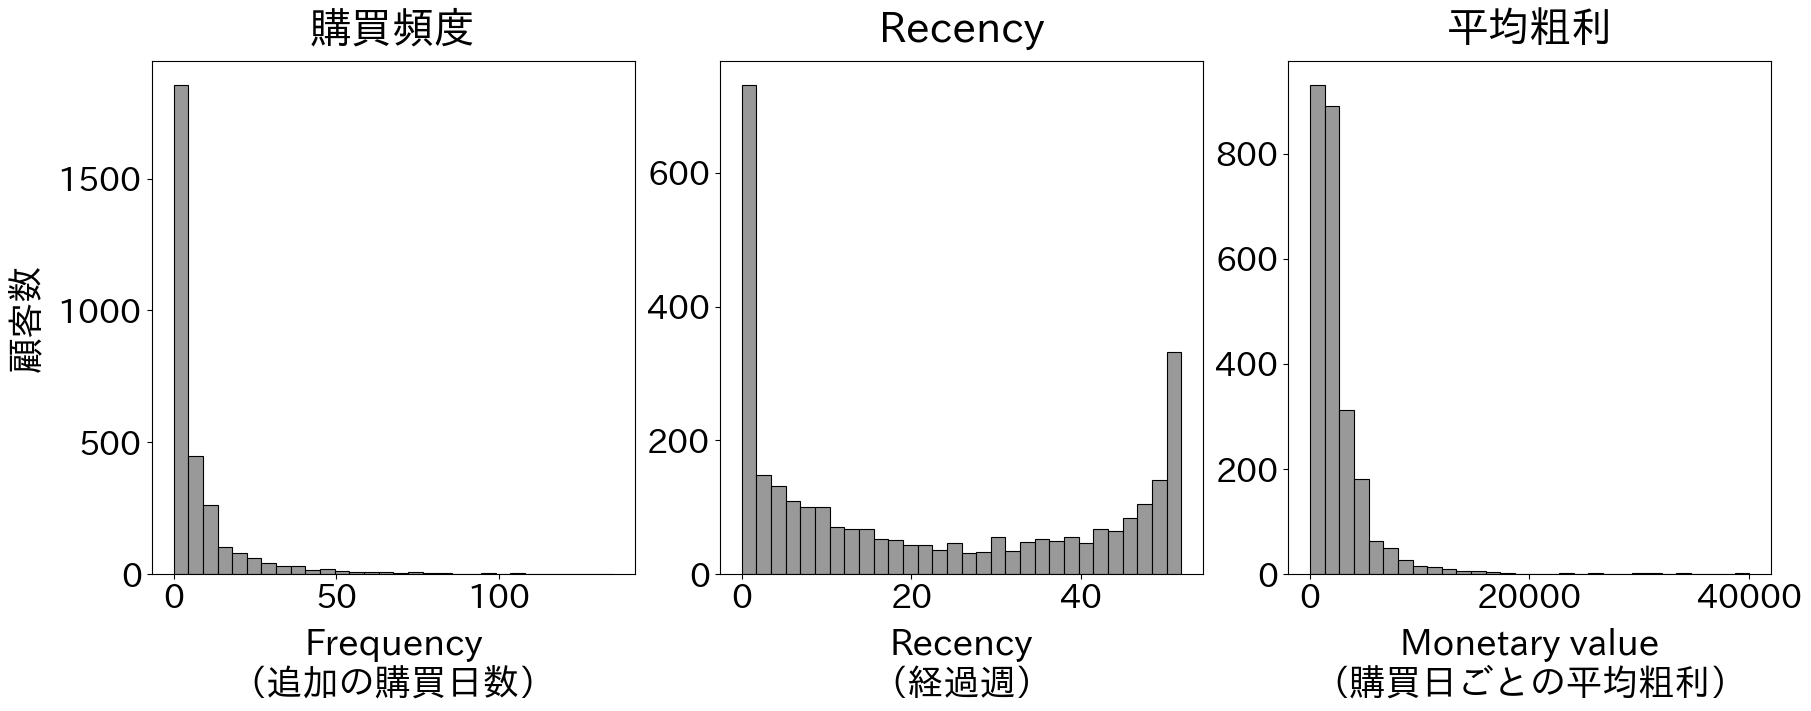

In [5]:
# 基本的な分布の確認
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 7), constrained_layout=True)
hist_style = {"color": "0.60", "edgecolor": "black", "linewidth": 0.8}

axes[0].hist(rfm_pl["frequency"].to_numpy(), bins=30, **hist_style)
axes[0].set_xlabel("Frequency\n（追加の購買日数）", fontsize=26, labelpad=10)
axes[0].set_ylabel("顧客数", fontsize=26, labelpad=10)
axes[0].set_title("購買頻度", fontsize=30, pad=14)
axes[0].tick_params(labelsize=24)

axes[1].hist(rfm_pl["recency"].to_numpy(), bins=30, **hist_style)
axes[1].set_xlabel("Recency\n（経過週）", fontsize=26, labelpad=10)
axes[1].set_title("Recency", fontsize=30, pad=14)
axes[1].tick_params(labelsize=24)

axes[2].hist(
    rfm_pl.filter(pl.col("monetary_value") > 0)["monetary_value"].to_numpy(),
    bins=30,
    **hist_style,
)
axes[2].set_xlabel(
    "Monetary value\n（購買日ごとの平均粗利）", fontsize=26, labelpad=10
)
axes[2].set_title("平均粗利", fontsize=30, pad=14)
axes[2].tick_params(labelsize=24)

plt.show()

## 第10章、第4節、第1項のコード

### データ準備：RFMのサマリーテーブルの確認と前処理 — 1回購買者の割合

`frequency=0`（初回の購買後に追加の購買日がない顧客）の比率を確認する。


In [6]:
# 1回しか購買していない顧客（frequency=0）の割合
n_one_time = rfm_pl.filter(pl.col("frequency") == 0).height
print(
    f"1回購買のみの顧客: {n_one_time} / {len(rfm_pl)} "
    f"({n_one_time / len(rfm_pl) * 100:.1f}%)"
)

1回購買のみの顧客: 487 / 3000 (16.2%)


## 第10章、第4節、第2項のコード

### BG/NBDモデルの学習と生存確率の図示 — BG/NBDモデルの当てはめ

`lifetimes.BetaGeoFitter` を使ってRFMのサマリーテーブルからBG/NBDモデルのパラメータ（r, alpha, a, b）を最尤推定（観測された購買履歴が最も得られやすくなるパラメータを選ぶ方法）する。

#### 処理内容

1. **BG/NBDモデルの学習**
   L2正則化（推定値が極端になりすぎないように抑える方法）の強さを決めるハイパーパラメータ（モデルを学習する前に人が設定する値）`penalizer_coef` を 0.001 とし、`BetaGeoFitter` を当てはめる。

2. **パラメータの確認**
   推定された r・alpha・a・b と、購買率の顧客間平均（r/alpha）・購買直後の離反確率の顧客間平均（a/(a+b)）を出力する。


In [7]:
from lifetimes import BetaGeoFitter

# BG/NBDモデルの当てはめ
bgf = BetaGeoFitter(
    penalizer_coef=0.001
)  # L2正則化（推定値が極端になりすぎないように抑える方法）
bgf.fit(
    frequency=rfm_pl["frequency"].to_numpy(),
    recency=rfm_pl["recency"].to_numpy(),
    T=rfm_pl["T"].to_numpy(),
)

summary_df = (
    bgf.summary.reset_index().rename(columns={"index": "parameter"}).round(4)
)

print(bgf.summary)
print("\n推定したパラメータ:")
print(f"  r     = {bgf.params_['r']:.4f}  (購買率のガンマ分布の形状パラメータ)")
print(
    f"  alpha = {bgf.params_['alpha']:.4f}  (購買率のガンマ分布のレートパラメータ)"
)
print(f"  a     = {bgf.params_['a']:.4f}  (離反確率のベータパラメータa)")
print(f"  b     = {bgf.params_['b']:.4f}  (離反確率のベータパラメータb)")
print(
    f"\n購買率の顧客間平均（r/alpha）: {bgf.params_['r'] / bgf.params_['alpha']:.4f} 回/週"
)
print(
    f"購買直後の離反確率の顧客間平均（a/(a+b)）: {bgf.params_['a'] / (bgf.params_['a'] + bgf.params_['b']):.4f}"
)

           coef  se(coef)  lower 95% bound  upper 95% bound
r      0.526328  0.014662         0.497590         0.555066
alpha  1.513623  0.064349         1.387499         1.639747
a      0.477357  0.025136         0.428090         0.526624
b      2.147350  0.165323         1.823316         2.471383

推定したパラメータ:
  r     = 0.5263  (購買率のガンマ分布の形状パラメータ)
  alpha = 1.5136  (購買率のガンマ分布のレートパラメータ)
  a     = 0.4774  (離反確率のベータパラメータa)
  b     = 2.1473  (離反確率のベータパラメータb)

購買率の顧客間平均（r/alpha）: 0.3477 回/週
購買直後の離反確率の顧客間平均（a/(a+b)）: 0.1819


## 第10章、第4節、第2項のコード

### BG/NBDモデルの学習と生存確率の図示 — 推定したパラメータの再確認

BG/NBDモデルで推定したパラメータと、購買率・購買直後の離反確率の顧客間平均を再確認する。


In [8]:
print("推定したパラメータ:")
print(f"  r     = {bgf.params_['r']:.4f}  (購買率のガンマ分布の形状パラメータ)")
print(
    f"  alpha = {bgf.params_['alpha']:.4f}  (購買率のガンマ分布のレートパラメータ)"
)
print(f"  a     = {bgf.params_['a']:.4f}  (離反確率のベータパラメータa)")
print(f"  b     = {bgf.params_['b']:.4f}  (離反確率のベータパラメータb)")
print(
    f"\n購買率の顧客間平均（r/alpha）: {bgf.params_['r'] / bgf.params_['alpha']:.4f} 回/週"
)
print(
    f"購買直後の離反確率の顧客間平均（a/(a+b)）: {bgf.params_['a'] / (bgf.params_['a'] + bgf.params_['b']):.4f}"
)

推定したパラメータ:
  r     = 0.5263  (購買率のガンマ分布の形状パラメータ)
  alpha = 1.5136  (購買率のガンマ分布のレートパラメータ)
  a     = 0.4774  (離反確率のベータパラメータa)
  b     = 2.1473  (離反確率のベータパラメータb)

購買率の顧客間平均（r/alpha）: 0.3477 回/週
購買直後の離反確率の顧客間平均（a/(a+b)）: 0.1819


## 第10章、第4節、第2項のコード

### BG/NBDモデルの学習と生存確率の図示 — 観測期間内の当てはまり

`lifetimes.plotting.plot_period_transactions` で、学習に使った観測期間内の追加の購買日数0〜6日について、実測値とBG/NBDモデルから生成した値を比較する。この図は将来の予測精度を示すものではない。

#### 処理内容

1. **当てはまりを確認するグラフの作成**
   `plot_period_transactions(bgf)` で実測値とモデル生成値の棒グラフを重ねて表示する。


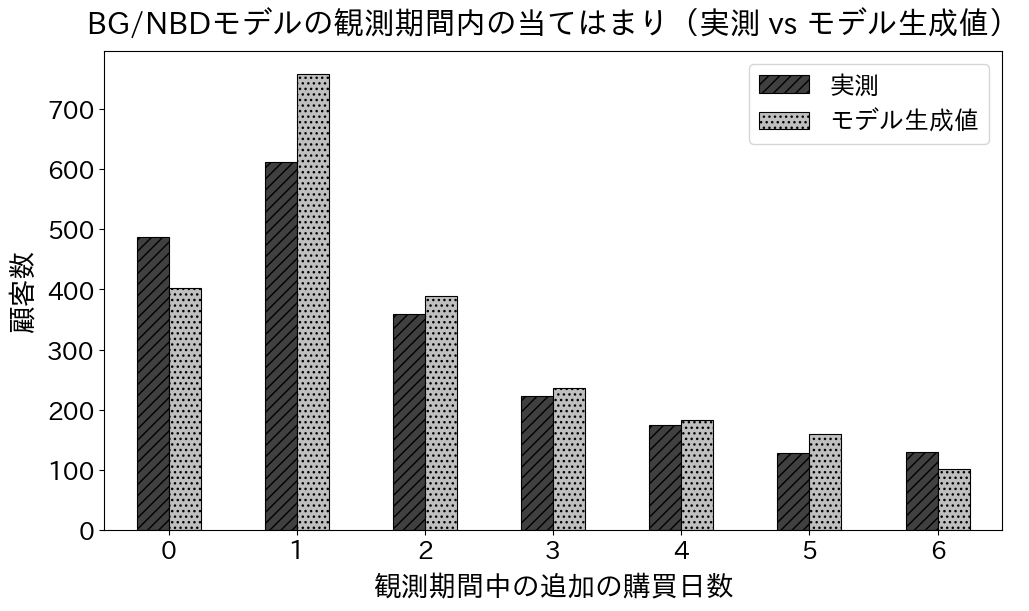

In [9]:
import matplotlib.pyplot as plt
from lifetimes.plotting import plot_period_transactions
from matplotlib import ticker

np.random.seed(123)  # モデル生成値を毎回同じにする

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
plot_period_transactions(
    bgf,
    max_frequency=7,  # 0〜6日を表示
    ax=ax,
    color=["0.25", "0.75"],
    edgecolor="black",
    linewidth=0.8,
)

for bars, hatch in zip(ax.containers, ("///", "...")):
    for bar in bars:
        bar.set_hatch(hatch)

ax.set_title(
    "BG/NBDモデルの観測期間内の当てはまり（実測 vs モデル生成値）",
    fontsize=22,
    pad=12,
)
ax.set_xlabel("観測期間中の追加の購買日数", fontsize=20, labelpad=8)
ax.set_ylabel("顧客数", fontsize=20, labelpad=8)
ax.tick_params(labelsize=18)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x)}"))
plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["実測", "モデル生成値"], fontsize=18)

plt.show()

## 第10章、第4節、第2項のコード

### BG/NBDモデルの学習と生存確率の図示 — 学習に使っていない期間での確認

観測期間を学習用と確認用に分け、確認用期間の購買日数を予測する。予測と実績の平均絶対誤差（差の絶対値の平均）を計算し、グラフでも比べる。


確認用期間の平均絶対誤差: 0.761日


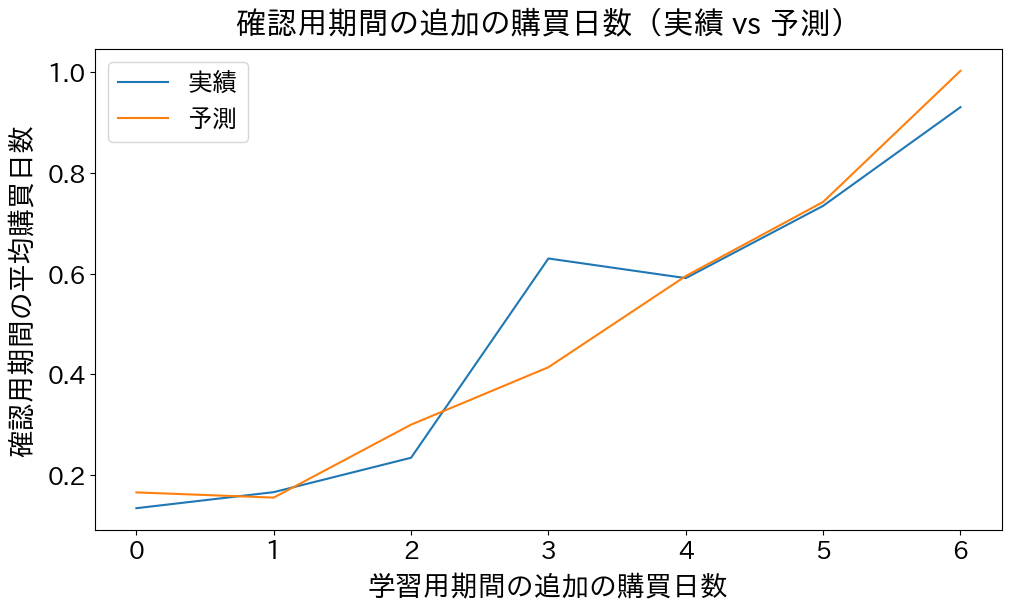

In [10]:
from lifetimes.plotting import plot_calibration_purchases_vs_holdout_purchases
from lifetimes.utils import calibration_and_holdout_data

calibration_end = np.datetime64("2022-09-30")
rfm_cal_holdout = calibration_and_holdout_data(
    transactions=transaction_log_pd,
    customer_id_col="customer_id",
    datetime_col="date",
    calibration_period_end=calibration_end,
    observation_period_end=observation_end,
    monetary_value_col="gross_profit",
    freq="D",
    freq_multiplier=7,
)

bgf_holdout = BetaGeoFitter(penalizer_coef=0.001)
bgf_holdout.fit(
    frequency=rfm_cal_holdout["frequency_cal"],
    recency=rfm_cal_holdout["recency_cal"],
    T=rfm_cal_holdout["T_cal"],
)

holdout_weeks = float(rfm_cal_holdout["duration_holdout"].iloc[0])
predicted_holdout = (
    bgf_holdout.conditional_expected_number_of_purchases_up_to_time(
        t=holdout_weeks,
        frequency=rfm_cal_holdout["frequency_cal"],
        recency=rfm_cal_holdout["recency_cal"],
        T=rfm_cal_holdout["T_cal"],
    )
)
holdout_mae = np.mean(
    np.abs(predicted_holdout - rfm_cal_holdout["frequency_holdout"])
)
print(f"確認用期間の平均絶対誤差: {holdout_mae:.3f}日")

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
plot_calibration_purchases_vs_holdout_purchases(
    bgf_holdout, rfm_cal_holdout, ax=ax
)
ax.set_title("確認用期間の追加の購買日数（実績 vs 予測）", fontsize=22, pad=12)
ax.set_xlabel("学習用期間の追加の購買日数", fontsize=20, labelpad=8)
ax.set_ylabel("確認用期間の平均購買日数", fontsize=20, labelpad=8)
ax.tick_params(labelsize=18)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["実績", "予測"], fontsize=18)
plt.show()

## 第10章、第4節、第2項のコード

### BG/NBDモデルの学習と生存確率の図示 — 各顧客の生存確率の算出

`bgf.conditional_probability_alive` で各顧客の現在の生存確率（P(alive)）を計算し、複数回購買者の上位5名を確認する。

#### 処理内容

1. **生存確率の計算**
   RFMのサマリーテーブルの frequency・recency・T を渡して顧客ごとの生存確率を算出する。

2. **上位5名の確認**
   `frequency > 0`（複数回購買者）に絞り、生存確率の高い順に上位5名を表示する。


In [11]:
# 各顧客の生存確率を計算
prob_alive = bgf.conditional_probability_alive(
    frequency=rfm_pl["frequency"].to_numpy(),
    recency=rfm_pl["recency"].to_numpy(),
    T=rfm_pl["T"].to_numpy(),
)

rfm_with_alive = rfm_pl.with_columns(pl.Series("prob_alive", prob_alive))

# 複数回購買者に絞って上位5名を確認
print("生存確率 上位5名（複数回購買者）:")
rfm_alive_repeat_top = (
    rfm_with_alive.filter(pl.col("frequency") > 0)
    .sort(["prob_alive", "frequency"], descending=[True, True])
    .select(["customer_id", "frequency", "recency", "T", "prob_alive"])
    .head(5)
)
format_table_for_display(rfm_alive_repeat_top.to_pandas())

生存確率 上位5名（複数回購買者）:


,customer_id,frequency,recency,T,prob_alive
0,1476,99,51.86,52.00,99.38%
1,1836,87,51.86,52.00,99.32%
2,2422,83,51.86,52.00,99.30%
3,2697,135,51.71,52.00,99.28%
4,1170,129,51.71,52.00,99.27%


## 第10章、第4節、第2項のコード

### BG/NBDモデルの学習と生存確率の図示 — RecencyとFrequencyの組み合わせ

`lifetimes.plotting.plot_probability_alive_matrix` で Recency × Frequency の組み合わせに対する生存確率を、値の大小を色の濃淡で表す図（ヒートマップ）にする。

#### 処理内容

1. **生存確率を表す図の作成**
   `plot_probability_alive_matrix(bgf)` で図を生成する。


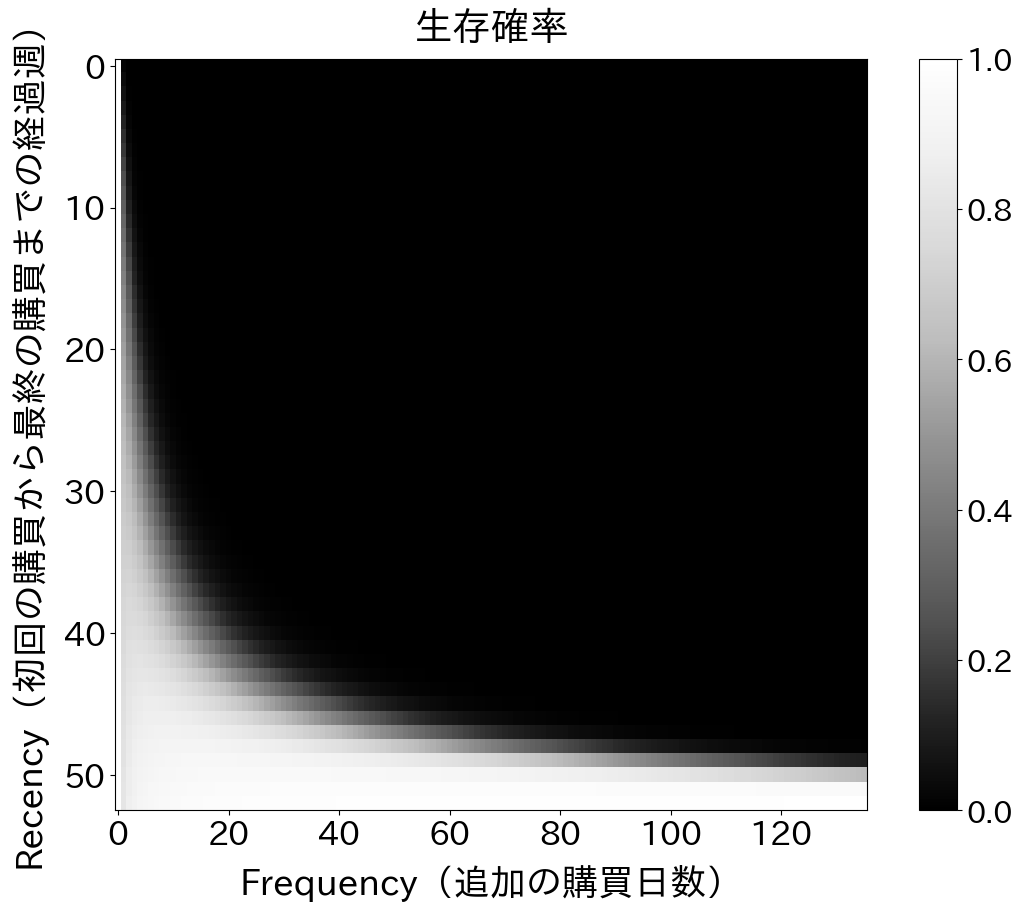

In [12]:
import matplotlib.pyplot as plt
from lifetimes.plotting import plot_probability_alive_matrix

fig = plt.figure(figsize=(12, 9), constrained_layout=True)
ax = plot_probability_alive_matrix(
    bgf,
    cmap="Greys_r",
    vmin=0,
    vmax=1,
)
ax.set_title("生存確率", fontsize=28, pad=14)
ax.set_xlabel("Frequency（追加の購買日数）", fontsize=26, labelpad=10)
ax.set_ylabel(
    "Recency（初回の購買から最終の購買までの経過週）", fontsize=26, labelpad=12
)
ax.tick_params(labelsize=24)

# カラーバーのラベルを大きくする
for colorbar_ax in fig.axes:
    if colorbar_ax is not ax:
        colorbar_ax.tick_params(labelsize=22)
        colorbar_ax.yaxis.label.set_fontsize(24)

plt.show()

## 第10章、第4節、第3項のコード

### 将来の追加の購買日数の予測とLTVの算出 — BG/NBDによる期待値の予測

`bgf.conditional_expected_number_of_purchases_up_to_time` で各顧客の将来52週間（約1年）における追加の購買日数の期待値を予測する。

#### 処理内容

1. **将来の追加の購買日数の予測**
   `t_future=52`（週）として、条件を反映した追加の購買日数の期待値を計算し、RFMのサマリーテーブルに追加する。

2. **予測上位5名の確認**
   予測した追加の購買日数の降順で上位5名を表示する。


In [13]:
# 将来52週間（約1年）の追加の購買日数を予測
t_future = 52  # 予測期間（週）

predicted_purchases = bgf.conditional_expected_number_of_purchases_up_to_time(
    t=t_future,
    frequency=rfm_pl["frequency"].to_numpy(),
    recency=rfm_pl["recency"].to_numpy(),
    T=rfm_pl["T"].to_numpy(),
)

rfm_pred = rfm_with_alive.with_columns(
    pl.Series("predicted_purchases", predicted_purchases)
)

print(f"将来{t_future}週間の予測した追加の購買日数（上位5名）:")

pred_top5 = (
    rfm_pred.sort("predicted_purchases", descending=True)
    .select(
        [
            "customer_id",
            "frequency",
            "recency",
            "T",
            "prob_alive",
            "predicted_purchases",
        ]
    )
    .head()
)
format_table_for_display(pred_top5.to_pandas())

将来52週間の予測した追加の購買日数（上位5名）:


,customer_id,frequency,recency,T,prob_alive,predicted_purchases
0,2697,135,51.71,52.00,99.28%,109.77
1,1170,129,51.71,52.00,99.27%,104.91
2,2299,114,50.71,52.00,93.71%,87.57
3,2956,107,51.71,52.00,99.22%,87.07
4,1394,105,51.29,52.00,98.18%,84.55


## 第10章、第4節、第3項のコード

### 将来の追加の購買日数の予測とLTVの算出 — 購買日ごとの平均粗利の予測：ガンマ-ガンマモデル

`lifetimes.GammaGammaFitter` を複数回購買者のデータに当てはめ、顧客ごとの購買日ごとの平均粗利を確率分布で表す。

#### 処理内容

1. **データの絞り込み**
   `frequency > 0` の顧客（複数回購買者）のみを対象とする。

2. **ガンマ-ガンマモデルの当てはめ**
   `penalizer_coef=0.0` で `GammaGammaFitter` を当てはめる。

3. **前提条件の確認**
   顧客全体の期待粗利を有限にする条件である `q > 1` を確認し、パラメータ一覧を表示する。


In [14]:
from lifetimes import GammaGammaFitter

# frequencyが1以上の顧客のみを対象（複数回購買者）
rfm_repeat = rfm_pred.filter(pl.col("frequency") > 0)

ggf = GammaGammaFitter(penalizer_coef=0.0)
ggf.fit(
    frequency=rfm_repeat["frequency"].to_numpy(),
    monetary_value=rfm_repeat["monetary_value"].to_numpy(),
)

if ggf.params_["q"] <= 1:
    raise ValueError("顧客全体の期待粗利を有限にするため、q > 1 が必要です。")

ggf_summary = (
    ggf.summary.reset_index()
    .rename(columns={"index": "parameter"})
    .round(4)
    .set_index("parameter")
)
format_table_for_display(ggf_summary)

,coef,se(coef),lower 95% bound,upper 95% bound
parameter,,,,
p,1.94,0.13,1.68,2.20
q,2.92,0.11,2.69,3.14
v,2466.36,247.13,1982.00,2950.73


## 第10章、第4節、第3項のコード

### 将来の追加の購買日数の予測とLTVの算出 — ガンマ-ガンマモデルのパラメータと前提条件の確認

推定したパラメータ p・q・v を確認する。p は同じ顧客の粗利のばらつきを表すガンマ分布の形状、q は ν_i の分布の形状、v は ν_i の分布のレートパラメータで、理論式の γ に対応する。また、追加の購買日数と購買日ごとの平均粗利の関係を相関係数（2つの値が一緒に増減する度合いを表す値）で簡単に点検する。ただし、相関係数が0に近くても独立であることを保証するものではない。相関が強い場合は、原因を確認して顧客をセグメントに分け、セグメントごとにモデルを学習して相関を再確認する。


In [15]:
print("推定したパラメータ:")
print(f"  p = {ggf.params_['p']:.4f}")
print(f"  q = {ggf.params_['q']:.4f}")
print(f"  v = {ggf.params_['v']:.4f}")
print(f"  q > 1: {ggf.params_['q'] > 1}")

# 追加の購買日数と購買日ごとの平均粗利を相関係数で点検
corr = rfm_repeat.select([pl.corr("frequency", "monetary_value").alias("corr")])
print(
    f"\n追加の購買日数と購買日ごとの平均粗利の相関係数: {corr['corr'][0]:.4f}"
)
print("（相関係数は前提を点検する目安であり、独立であることを保証しません）")

推定したパラメータ:
  p = 1.9400
  q = 2.9166
  v = 2466.3650
  q > 1: True

追加の購買日数と購買日ごとの平均粗利の相関係数: 0.0179
（相関係数は前提を点検する目安であり、独立であることを保証しません）


## 第10章、第4節、第3項のコード

### 将来の追加の購買日数の予測とLTVの算出 — 将来の追加の購買日数と購買日ごとの期待粗利

`ggf.customer_lifetime_value` でBG/NBDモデルとガンマ-ガンマモデルを組み合わせ、今後12ヶ月の顧客ごとの粗利ベースのLTVを算出する。

#### 処理内容

1. **LTV の算出**
   `time=12`（月）、`discount_rate=0.01`（月次割引率1%≒実効年率12.7%）、`freq="W"` で `customer_lifetime_value` を呼び出す。

2. **Polars への変換と結合**
   算出したLTVをPolarsのDataFrameに変換し、RFMのサマリーテーブルと結合して `LTV` 列として追加する。

3. **LTV 上位5名の確認**
   LTVが高い順に上位5名を表示する。


In [16]:
# LTVを算出（全顧客に対して）
rfm_pred_pd = rfm_pred.to_pandas().set_index("customer_id")

ltv_values = ggf.customer_lifetime_value(
    transaction_prediction_model=bgf,
    frequency=rfm_pred_pd["frequency"],
    recency=rfm_pred_pd["recency"],
    T=rfm_pred_pd["T"],
    monetary_value=rfm_pred_pd["monetary_value"],
    time=12,  # 予測期間（月）
    discount_rate=0.01,  # 月次割引率（実効年率約12.7%相当）
    freq="W",  # 観測の時間単位（週）
)

# Polarsに戻して元のRFMのサマリーテーブルと結合
ltv_pl = pl.from_pandas(ltv_values.reset_index())
ltv_pl.columns = ["customer_id", "ltv"]
rfm_final = rfm_pred.join(ltv_pl, on="customer_id", how="left").with_columns(
    [
        pl.col("monetary_value").cast(pl.Int64),
        pl.col("ltv").cast(pl.Int64),
    ]
)

# ltv を LTV にリネーム
rfm_final = rfm_final.rename({"ltv": "LTV"})

print("粗利ベースのLTV（上位5名）:")
rfm_clv_top5 = (
    rfm_final.sort("LTV", descending=True)
    .select(
        [
            "customer_id",
            "frequency",
            "recency",
            "T",
            "prob_alive",
            "predicted_purchases",
            "monetary_value",
            "LTV",
        ]
    )
    .head(5)
)
format_table_for_display(rfm_clv_top5.to_pandas())

粗利ベースのLTV（上位5名）:


,customer_id,frequency,recency,T,prob_alive,predicted_purchases,monetary_value,LTV
0,2299,114,50.71,52.00,93.71%,87.57,"11,680","958,125"
1,50,62,51.43,52.00,98.54%,50.33,"13,534","634,208"
2,2422,83,51.86,52.00,99.30%,67.71,"7,777","492,647"
3,1799,96,51.43,52.00,98.63%,77.71,"5,249","382,649"
4,1170,129,51.71,52.00,99.27%,104.91,"3,873","382,230"


## 第10章、第4節、第4項のコード

### 粗利ベースのLTVに基づくVIP顧客のランキング作成 — セグメントへの分類

算出したLTVを高い順に並べ、累積構成比（パレート分析）に基づいて顧客を Platinum・Gold・Silver・General の4セグメントに分類する。

#### 処理内容

1. **LTVが高い順への並べ替えと順位付け**
   `with_row_index("rank", offset=1)` でランクを付与する。

2. **LTVの累積割合の計算**
   `cum_sum() / total_ltv * 100` で累積割合（%）を算出する。

3. **セグメントへの分類**
   累積割合 ≤30% → Platinum、≤60% → Gold、≤85% → Silver、それ以外 → General と分類する。30%・60%・85%は運用上の設定値とする。

4. **VIP顧客のランキング上位5名の確認**
   rank・customer_id・frequency・recency・prob_alive・LTV・cumulative_ltv_pct・segment を表示する。


In [17]:
import numpy as np

# LTVが高い順に並べる（LTVが欠損値（Null）の顧客は除外）
rfm_ranked = (
    rfm_final.drop_nulls("LTV")
    .sort("LTV", descending=True)
    .with_row_index("rank", offset=1)
)

# LTVの累積割合を計算
total_ltv = rfm_ranked["LTV"].sum()
rfm_ranked = rfm_ranked.with_columns(
    (pl.col("LTV").cum_sum() / total_ltv * 100).alias("cumulative_ltv_pct")
)


# セグメントへの分類：累積割合に基づく
SEGMENT_THRESHOLDS = (("Platinum", 30), ("Gold", 60), ("Silver", 85))


def assign_segment(cumulative_pct: float) -> str:
    for segment, upper_bound in SEGMENT_THRESHOLDS:
        if cumulative_pct <= upper_bound:
            return segment
    return "General"


rfm_ranked = rfm_ranked.with_columns(
    pl.col("cumulative_ltv_pct")
    .map_elements(assign_segment, return_dtype=pl.Utf8)
    .alias("segment")
)

print("VIP顧客のランキング（上位5名）:")
rfm_ranked_top5 = rfm_ranked.select(
    [
        "rank",
        "customer_id",
        "frequency",
        "recency",
        "prob_alive",
        "LTV",
        "cumulative_ltv_pct",
        "segment",
    ]
).head(5)
format_table_for_display(rfm_ranked_top5.to_pandas())

VIP顧客のランキング（上位5名）:


,rank,customer_id,frequency,recency,prob_alive,LTV,cumulative_ltv_pct,segment
0,1,2299,114,50.71,93.71%,"958,125",3.34%,Platinum
1,2,50,62,51.43,98.54%,"634,208",5.54%,Platinum
2,3,2422,83,51.86,99.30%,"492,647",7.26%,Platinum
3,4,1799,96,51.43,98.63%,"382,649",8.59%,Platinum
4,5,1170,129,51.71,99.27%,"382,230",9.92%,Platinum


## 第10章、第4節、第4項のコード

### 粗利ベースのLTVに基づくVIP顧客のランキング作成 — セグメントごとの集計

各セグメント（Platinum・Gold・Silver・General）の顧客数・平均LTV・LTV合計・平均生存確率・LTVの割合を集計する。


In [18]:
# セグメントごとの集計
segment_summary = (
    rfm_ranked.group_by("segment")
    .agg(
        [
            pl.len().alias("顧客数"),
            pl.col("LTV").mean().alias("平均LTV"),
            pl.col("LTV").sum().alias("LTV合計"),
            pl.col("prob_alive").mean().alias("平均生存確率"),
        ]
    )
    .with_columns((pl.col("LTV合計") / total_ltv * 100).alias("LTVの割合(%)"))
    .sort("LTV合計", descending=True)
)

print("セグメントごとの集計:")
print(segment_summary)

# セグメントごとの顧客数比率
n_total = rfm_ranked.height
for row in segment_summary.iter_rows(named=True):
    pct = row["顧客数"] / n_total * 100
    print(
        f"{row['segment']:10s}: {row['顧客数']:4d}名 ({pct:.1f}%) "
        f"| 平均LTV: {row['平均LTV']:8.0f}円 "
        f"| LTVの割合: {row['LTVの割合(%)']:.1f}%"
    )

セグメントごとの集計:
shape: (4, 6)
┌──────────┬────────┬───────────────┬─────────┬──────────────┬──────────────┐
│ segment  ┆ 顧客数 ┆ 平均LTV       ┆ LTV合計 ┆ 平均生存確率 ┆ LTVの割合(%) │
│ ---      ┆ ---    ┆ ---           ┆ ---     ┆ ---          ┆ ---          │
│ str      ┆ u32    ┆ f64           ┆ i64     ┆ f64          ┆ f64          │
╞══════════╪════════╪═══════════════╪═════════╪══════════════╪══════════════╡
│ Gold     ┆ 117    ┆ 74087.435897  ┆ 8668230 ┆ 0.945804     ┆ 30.175921    │
│ Platinum ┆ 31     ┆ 275719.516129 ┆ 8547305 ┆ 0.965074     ┆ 29.754956    │
│ Silver   ┆ 329    ┆ 21856.784195  ┆ 7190882 ┆ 0.881274     ┆ 25.032964    │
│ General  ┆ 2523   ┆ 1711.944114   ┆ 4319235 ┆ 0.437958     ┆ 15.03616     │
└──────────┴────────┴───────────────┴─────────┴──────────────┴──────────────┘
Gold      :  117名 (3.9%) | 平均LTV:    74087円 | LTVの割合: 30.2%
Platinum  :   31名 (1.0%) | 平均LTV:   275720円 | LTVの割合: 29.8%
Silver    :  329名 (11.0%) | 平均LTV:    21857円 | LTVの割合: 25.0%
General   : 2523名 (84.1%) | 平

## 第10章、第4節、第4項のコード

### 粗利ベースのLTVに基づくVIP顧客のランキング作成 — 分布とランキングの図示

粗利ベースのLTVの分布を値が一定の倍率で増える対数目盛で示し、上位顧客から順に積み上げたLTVの累積割合の曲線（パレート曲線）と並べる。

#### 処理内容

1. **LTVの分布（対数目盛）**
   リピート購買者のLTVを対数目盛で表示し、分布の偏りを確認する。

2. **LTVの累積割合の曲線（パレート曲線）**
   顧客の順位が上位 X% までの顧客が全LTVに占める累積割合を折れ線で表示する。
   セグメントの区切り（Platinum・Gold・Silver のLTVの累積割合の基準値）を破線で追加する。


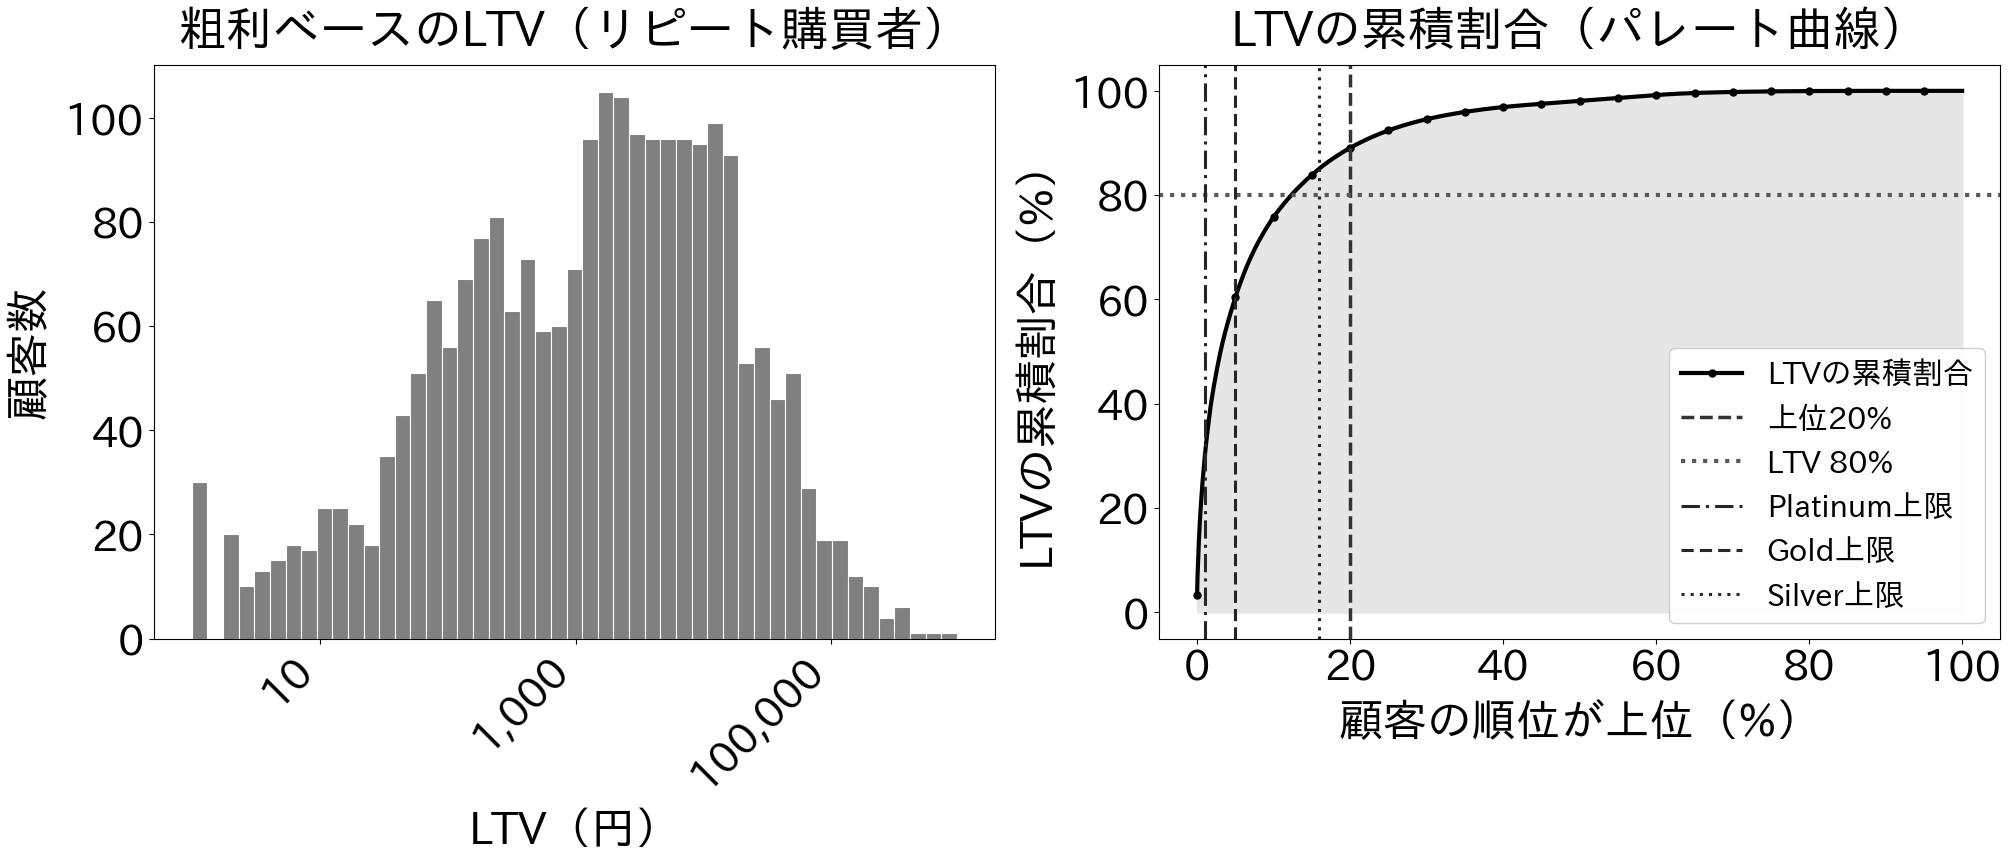

In [19]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import ticker

fig, axes = plt.subplots(1, 2, figsize=(20, 8.5), constrained_layout=True)

# 左：LTVの分布（x軸は対数目盛、リピート購買者のみ）
ax1 = axes[0]
ltv_vals = rfm_ranked.filter((pl.col("LTV") > 0) & (pl.col("frequency") > 0))[
    "LTV"
].to_numpy()
bins = np.logspace(np.log10(ltv_vals.min()), np.log10(ltv_vals.max()), 50)
ax1.hist(ltv_vals, bins=bins, color="0.50", edgecolor="white", linewidth=0.8)
ax1.set_xscale("log")
ax1.set_title("粗利ベースのLTV（リピート購買者）", fontsize=34, pad=14)
ax1.set_xlabel("LTV（円）", fontsize=32, labelpad=10)
ax1.set_ylabel("顧客数", fontsize=32, labelpad=10)
ax1.tick_params(labelsize=30)
ax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")

# 右：LTVの累積割合の曲線（パレート曲線）
ax2 = axes[1]
x_pct = (rfm_ranked["rank"] / rfm_ranked.height * 100).to_numpy()
y_pct = rfm_ranked["cumulative_ltv_pct"].to_numpy()
markevery = max(1, len(x_pct) // 20)
ax2.plot(
    x_pct,
    y_pct,
    color="black",
    linewidth=3,
    marker="o",
    markersize=5,
    markevery=markevery,
    label="LTVの累積割合",
)
ax2.axvline(x=20, color="0.20", linestyle="--", linewidth=2.5, label="上位20%")
ax2.axhline(y=80, color="0.35", linestyle=":", linewidth=3, label="LTV 80%")
ax2.fill_between(x_pct, y_pct, color="0.90")
ax2.set_title("LTVの累積割合（パレート曲線）", fontsize=34, pad=14)
ax2.set_xlabel("顧客の順位が上位（%）", fontsize=32, labelpad=10)
ax2.set_ylabel("LTVの累積割合（%）", fontsize=32, labelpad=10)
ax2.tick_params(labelsize=30)

# セグメント境界は濃淡ではなく線種でも区別する
segment_styles = {
    "Platinum": (0, (6, 2, 1, 2)),
    "Gold": (0, (4, 2)),
    "Silver": (0, (1, 2)),
}
for label, threshold in SEGMENT_THRESHOLDS:
    rank_at = (
        rfm_ranked.filter(pl.col("cumulative_ltv_pct") <= threshold).height
        / rfm_ranked.height
        * 100
    )
    ax2.axvline(
        x=rank_at,
        color="0.15",
        linestyle=segment_styles[label],
        linewidth=2.2,
        label=f"{label}上限",
    )

ax2.legend(fontsize=22, ncol=1, loc="lower right", framealpha=0.95)

plt.show()